In [33]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import calinski_harabasz_score
from yellowbrick.cluster import KElbowVisualizer
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

In [3]:
data = pd.read_csv('SouthGermanCredit.asc', sep=r'\s')
data

/tmp/ipykernel_1034/2140255779.py:1: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  data = pd.read_csv('SouthGermanCredit.asc', sep=r'\s')


,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,1,24,2,3,1987,1,3,2,3,1,...,1,21,3,1,1,2,1,1,2,0
996,1,24,2,0,2303,1,5,4,3,2,...,1,45,3,2,1,3,2,1,2,0
997,4,21,4,0,12680,5,5,4,3,1,...,4,30,3,3,1,4,2,2,2,0
998,2,12,2,3,6468,5,1,2,3,1,...,4,52,3,2,1,4,2,2,2,0


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   laufkont  1000 non-null   int64
 1   laufzeit  1000 non-null   int64
 2   moral     1000 non-null   int64
 3   verw      1000 non-null   int64
 4   hoehe     1000 non-null   int64
 5   sparkont  1000 non-null   int64
 6   beszeit   1000 non-null   int64
 7   rate      1000 non-null   int64
 8   famges    1000 non-null   int64
 9   buerge    1000 non-null   int64
 10  wohnzeit  1000 non-null   int64
 11  verm      1000 non-null   int64
 12  alter     1000 non-null   int64
 13  weitkred  1000 non-null   int64
 14  wohn      1000 non-null   int64
 15  bishkred  1000 non-null   int64
 16  beruf     1000 non-null   int64
 17  pers      1000 non-null   int64
 18  telef     1000 non-null   int64
 19  gastarb   1000 non-null   int64
 20  kredit    1000 non-null   int64
dtypes: int64(21)
memory usage: 164.2 KB


In [12]:
scaler = StandardScaler()
scaler.fit(data)
data_scaled = scaler.transform(data)

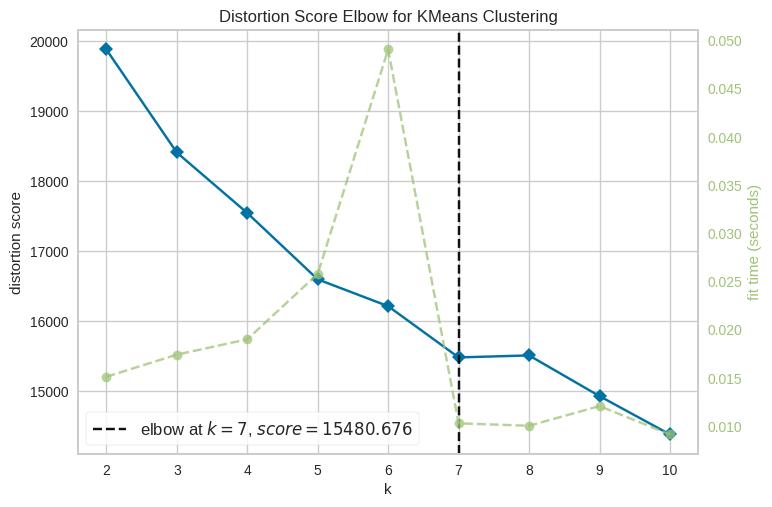

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [13]:
Elbow_1 = KElbowVisualizer(KMeans(), k=10)
Elbow_1.fit(data_scaled)
Elbow_1.show()

In [40]:
for n in range(2, 11):
  print(silhouette_score(data_scaled, KMeans(n_clusters=n, random_state=42).fit_predict(data_scaled)))

0.0825790230838109
0.07292543714131822
0.07113637981973492
0.08133409048229481
0.07254582646894084
0.06502497956719878
0.05878857133107796
0.07124369535992284
0.06115257057130597


In [41]:
for n in range(2, 11):
  print(calinski_harabasz_score(data_scaled, KMeans(n_clusters=n, random_state=42).fit_predict(data_scaled)))

84.03682387928636
76.76531948327724
62.507322409413504
66.73524494129134
57.21599543773351
56.7666684873455
52.37671774719121
53.10424323760747
46.25472143657498


According to the two last metrics, it is better to divide the dataset into 2 clusters.

In [42]:
for n in range(2, 11):
  print(silhouette_score(data_scaled, AgglomerativeClustering(n_clusters=n).fit_predict(data_scaled)))

0.12019273321109199
0.13474934774866398
0.06269809728839609
0.07304128579970984
0.06426647610986141
0.053373519854709776
0.047864558756575276
0.03546485206799063
0.041394088194976024


In [43]:
for n in range(2, 11):
  print(calinski_harabasz_score(data_scaled, AgglomerativeClustering(n_clusters=n).fit_predict(data_scaled)))

56.21181319636569
58.167100039876075
54.677147468204396
53.62587254096323
50.970929304345596
49.063697239056154
46.67004625603563
44.35914027176919
42.68398227589694


In agglomerative clustering it is better to divide into 3 clusters

In [44]:
clusters_1 = KMeans(n_clusters=2, random_state=42, n_init='auto').fit_predict(data_scaled)
clusters_2 = AgglomerativeClustering(n_clusters=2).fit_predict(data_scaled)

Text(0, 0.5, 'cumulative explained variance')

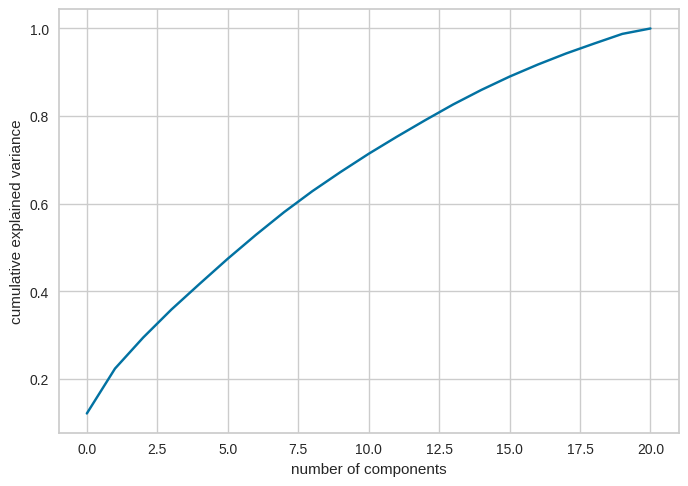

In [45]:
pca = PCA().fit(data_scaled)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')

In [46]:
print(np.cumsum(pca.explained_variance_ratio_)[10])

0.7140344205783353


11 features are enough in order not to lose over 30% of information

In [51]:
data_t = PCA(n_components=11, random_state=42).fit_transform(data_scaled)
for n in range(2, 11):
  print(silhouette_score(data_t, KMeans(n_clusters=n, random_state=42).fit_predict(data_t)))

0.10119994295661341
0.10558243964272314
0.08560597768183022
0.09207083485514156
0.08847887074031252
0.09811637182984205
0.09083814637381192
0.0922450634706221
0.08376279490566005


In [52]:
for n in range(2, 11):
  print(calinski_harabasz_score(data_t, KMeans(n_clusters=n, random_state=42).fit_predict(data_t))) #according to this metric it is better to divide into 4 clusters

107.91798316836301
113.63955386423252
97.78097739044611
96.3863257245341
88.22267508914132
83.37848267227196
78.62090808572792
75.91938798737888
70.11256690327849


After demension reduction it is better to divide the dataset into 3 clusters

In [53]:
for n in range(2, 11):
  print(silhouette_score(data_t, AgglomerativeClustering(n_clusters=n).fit_predict(data_t)))

0.12646726450648738
0.05506853452524945
0.06422143833310096
0.07590284567849073
0.06685500278481817
0.04926464456329973
0.05990518970761633
0.06717591190432678
0.07272064037221358


In [54]:
for n in range(2, 11):
  print(calinski_harabasz_score(data_t, AgglomerativeClustering(n_clusters=n).fit_predict(data_t)))

76.3692865246064
74.96852659155192
74.27885388220933
70.54336417217489
66.9429522360698
63.545686319195475
61.59506268487605
59.78117308720136
57.458732177756424


After dimension reduction it is better to divide into 2 clusters

In [55]:
clusters_3 = KMeans(n_clusters=2, random_state=42, n_init='auto').fit_predict(data_t)
clusters_4 = AgglomerativeClustering(n_clusters=2).fit_predict(data_t)

In [56]:
data['cluster'] = clusters_1
data['cluster_pca'] = clusters_3
data

,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,bishkred,beruf,pers,telef,gastarb,kredit,cluster,cluster_pca,cluster_2,cluster_pca_2
0,1,18,4,2,1049,1,2,4,2,1,...,1,3,2,1,2,1,0,1,0,0
1,1,9,4,0,2799,1,3,2,3,1,...,2,3,1,1,2,1,0,0,0,0
2,2,12,2,9,841,2,4,2,2,1,...,1,2,2,1,2,1,0,0,0,0
3,1,12,4,0,2122,1,3,3,3,1,...,2,2,1,1,1,1,0,0,0,0
4,1,12,4,0,2171,1,3,4,3,1,...,2,2,2,1,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,1,24,2,3,1987,1,3,2,3,1,...,1,2,1,1,2,0,0,1,0,0
996,1,24,2,0,2303,1,5,4,3,2,...,1,3,2,1,2,0,0,1,1,0
997,4,21,4,0,12680,5,5,4,3,1,...,1,4,2,2,2,0,1,0,1,1
998,2,12,2,3,6468,5,1,2,3,1,...,1,4,2,2,2,0,1,1,1,0


In [57]:
cross_table_1 = pd.crosstab(data['cluster'], data['cluster_pca'],
                          rownames=['clusters before PCA'],
                          colnames=['clusters after PCA'])
display(cross_table_1)

clusters after PCA,0,1
clusters before PCA,,
0,378,240
1,177,205


As we can see, 177 went from cluster 1 to cluster 0 and 240 - from cluster 0 to cluster 1. That means that around 41.7% changed the cluster.

In [58]:
data['cluster_2'] = clusters_2
data['cluster_pca_2'] = clusters_4
data

,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,bishkred,beruf,pers,telef,gastarb,kredit,cluster,cluster_pca,cluster_2,cluster_pca_2
0,1,18,4,2,1049,1,2,4,2,1,...,1,3,2,1,2,1,0,1,0,0
1,1,9,4,0,2799,1,3,2,3,1,...,2,3,1,1,2,1,0,0,0,0
2,2,12,2,9,841,2,4,2,2,1,...,1,2,2,1,2,1,0,0,0,0
3,1,12,4,0,2122,1,3,3,3,1,...,2,2,1,1,1,1,0,0,0,0
4,1,12,4,0,2171,1,3,4,3,1,...,2,2,2,1,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,1,24,2,3,1987,1,3,2,3,1,...,1,2,1,1,2,0,0,1,0,0
996,1,24,2,0,2303,1,5,4,3,2,...,1,3,2,1,2,0,0,1,1,0
997,4,21,4,0,12680,5,5,4,3,1,...,1,4,2,2,2,0,1,0,1,1
998,2,12,2,3,6468,5,1,2,3,1,...,1,4,2,2,2,0,1,1,1,0


In [59]:
cross_table_2 = pd.crosstab(data['cluster_2'], data['cluster_pca_2'],
                          rownames=['clusters before PCA'],
                          colnames=['clusters after PCA'])
display(cross_table_2)

clusters after PCA,0,1
clusters before PCA,,
0,751,113
1,32,104


Agglomerative clustering demonstrated a more stable result: only 32 went from cluster 1 to cluster0 and 113 - from cluster 0 to cluster 1. That makes 14.5%.